In [2]:
import numpy as np
from scipy import optimize, stats

In [3]:
on_time, up_to_20, up_to_60, over_60 = 94.7, 4.42, 0.79, 0.06
p_obs = np.array([on_time, up_to_20, up_to_60, over_60])
p_obs /= p_obs.sum()       # the shares add up to 99.97, so renormalize
counts = p_obs * 369_241   # ADA trips in that period

# Bucket edges in minutes from window start (the window is 30 min long)
edges = np.array([30.0, 50.0, 89.0])

In [4]:
C_EARLY = 5.0   # ASSUMPTION: vans arrive up to ~5 min before the window (the data can't identify this)

def cdf(x, mu, s, c=C_EARLY):      # shifted lognormal
    return stats.norm.cdf((np.log(x + c) - mu) / s)

def bucket_probs(mu, s, c=C_EARLY):
    F = cdf(edges, mu, s, c)
    return np.diff(np.concatenate([[0], F, [1]]))

def nll(theta):  # negative log-likelihood
    mu, log_s = theta
    p = bucket_probs(mu, np.exp(log_s), C_EARLY)
    return -np.sum(counts * np.log(np.clip(p, 1e-300, None)))

In [5]:
res = optimize.minimize(nll, x0=[np.log(10 + C_EARLY), np.log(0.6)], method="Nelder-Mead",
                        options=dict(xatol=1e-10, fatol=1e-10, maxiter=20000))
mu, s = res.x[0], np.exp(res.x[1])
c = C_EARLY

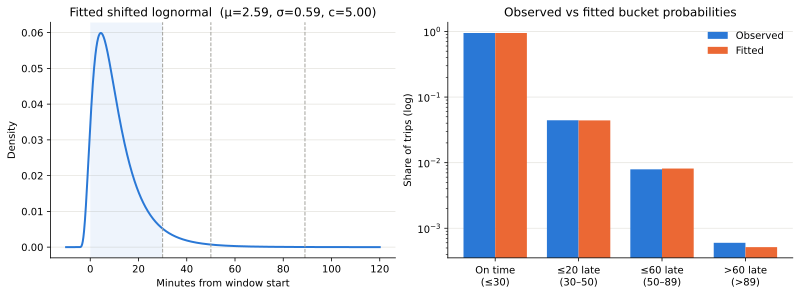

In [6]:
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = "svg"

dist = stats.lognorm(s, loc=-c, scale=np.exp(mu))   # same shifted lognormal as cdf()
x = np.linspace(-c - 5, 120, 1000)
labels = ["On time\n(≤30)", "≤20 late\n(30–50)", "≤60 late\n(50–89)", ">60 late\n(>89)"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

# Left: fitted arrival-time density, bucket edges marked
ax1.plot(x, dist.pdf(x), color="#2a78d6", lw=2)
for e in edges:
    ax1.axvline(e, color="#a3a29c", lw=1, ls="--")
ax1.axvspan(0, 30, color="#2a78d6", alpha=0.08, lw=0)
ax1.set(xlabel="Minutes from window start", ylabel="Density",
        title=f"Fitted shifted lognormal  (μ={mu:.2f}, σ={s:.2f}, c={c:.2f})")

# Right: observed vs fitted bucket shares (log scale – the tail is tiny)
p_fit = bucket_probs(mu, s, c)
i = np.arange(4); w = 0.38
ax2.bar(i - w/2, p_obs, w, label="Observed", color="#2a78d6")
ax2.bar(i + w/2, p_fit, w, label="Fitted", color="#eb6834")
ax2.set_yscale("log")
ax2.set_xticks(i, labels)
ax2.set(ylabel="Share of trips (log)", title="Observed vs fitted bucket probabilities")
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
plt.show()